In [1]:
%pip install kagglehub
%pip install scikit-learn
%pip install Pillow
%pip install matplotlib
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import kagglehub
import os
from pathlib import Path
import numpy as np
from sklearn.utils import shuffle
from PIL import Image
from tensorflow.keras.utils import img_to_array, load_img
from tensorflow import keras
import tensorflow as tf
from  tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint,ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, roc_auc_score
from keras.preprocessing import image_dataset_from_directory
from keras.applications import MobileNetV2
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.metrics import classification_report


# manuel

In [4]:
data_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)
print(os.listdir(data_path))
 

['chest_xray']


In [5]:
path = Path(data_path)

In [6]:
train_path = os.path.join(path,"chest_xray/chest_xray/","train")
test_path = os.path.join(path,"chest_xray/chest_xray/","test")
val_path = os.path.join(path,"chest_xray/chest_xray/","val")

print(test_path)

/root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/chest_xray/test


In [7]:
train_path_normal = os.path.join(train_path,"NORMAL")
train_path_pneumonia = os.path.join(train_path,"PNEUMONIA")

test_path_normal = os.path.join(test_path,"NORMAL")
test_path_pneumonia = os.path.join(test_path,"PNEUMONIA")

val_path_normal = os.path.join(val_path,"NORMAL")
val_path_pneumonia = os.path.join(val_path,"PNEUMONIA")


In [8]:
def corrupted_image(image) :
    try:
        with Image.open(image) as img:
           img.load()
        return False     
    except:
        return True    

In [9]:
def process_image(img):
    image = load_img(
        img,
        target_size=(180, 180),
        color_mode="rgb"
    )

    image = img_to_array(image) / 255.0
    image = np.asarray(image, dtype=np.float32)
    
    # else:    
    #     image = img_to_array(image)
    return image

In [10]:
def extract_image(data_image) :
   return  [
    process_image(img) for img in Path(data_image).rglob("*")
    if img.suffix.lower() in [".jpg", ".jpeg", ".png"]
    and not corrupted_image(img)
]

In [11]:
train_normal_images = extract_image(train_path_normal)
train_pneumonia_images = extract_image(train_path_pneumonia)

test_normal_images = extract_image(test_path_normal)
test_pneumonia_images = extract_image(test_path_pneumonia)

val_normal_images = extract_image(val_path_normal)
val_pneumonia_images = extract_image(val_path_pneumonia)

In [12]:
def convert_image (normal, pneumonia) :
   label_normal= np.zeros(len(normal))
   label_pneumonia = np.ones(len(pneumonia))

   X = np.concatenate((normal,pneumonia))
   y = np.concatenate((label_normal,label_pneumonia))

   return shuffle(X,y,random_state=42)

In [13]:
X_train, y_train = convert_image(train_normal_images , train_pneumonia_images) 
X_test, y_test = convert_image(test_normal_images , test_pneumonia_images) 
X_val, y_val = convert_image(val_normal_images , val_pneumonia_images) 
print(y_train.shape,y_test.shape,y_val.shape)

(5216,) (624,) (16,)


In [14]:
model = keras.Sequential([
    # Input images: height, width, RGB channels
    keras.Input(shape=(180, 180, 3)),

    # Feature extraction
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(
        filters=128,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    #NORMAL or PNEUMONIA
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ]
)

model.summary()

I0000 00:00:1793007332.275748     961 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 11532 MB memory:  -> device: 0, name: NVIDIA TITAN Xp, pci bus id: 0000:05:00.0, compute capability: 6.1


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,105 (25.36 MB)

 Trainable params: 6,647,105 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
early_stopping = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

In [16]:
def weights_equilibring() :
    
    classes = np.unique(y_train)


    weights = compute_class_weight(class_weight="balanced", classes=classes, y = y_train)

    class_weights = dict(zip(classes, weights))
    

    return class_weights

class_weights = weights_equilibring()

print(class_weights)

{np.float64(0.0): np.float64(1.9448173005219984), np.float64(1.0): np.float64(0.6730322580645162)}


In [17]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    class_weight = class_weights,
    validation_data=(X_val, y_val),
    callbacks = [early_stopping]
)

2026-10-26 09:35:34.298767: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 2027980800 exceeds 10% of free system memory.
2026-10-26 09:35:36.208720: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 2027980800 exceeds 10% of free system memory.


Epoch 1/10


I0000 00:00:1793007339.801766    1481 service.cc:152] XLA service 0x7f6d48002610 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793007339.801810    1481 service.cc:160]   StreamExecutor device (0): NVIDIA TITAN Xp, Compute Capability 6.1
2026-10-26 09:35:40.083556: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793007340.400143    1481 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-10-26 09:35:41.008235: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{} for conv %cudnn-conv-bias-activation.9 = (f32[32,32,178,178]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,3,180,180]{3,2,1,0} %bitcast.5273, f32[32,3,3,3]{3,2,1,0} %bitcast.5280, f32[32]{0} %bitcast.6120), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivati

  5/163 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.6214 - auc: 0.5511 - loss: 0.7920 - precision: 0.8700 - recall: 0.6369 

I0000 00:00:1793007343.980973    1481 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


162/163 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7749 - auc: 0.8564 - loss: 0.4404 - precision: 0.9215 - recall: 0.7655

2026-10-26 09:35:50.062179: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{} for conv %cudnn-conv-bias-activation.9 = (f32[16,32,178,178]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,3,180,180]{3,2,1,0} %bitcast.948, f32[32,3,3,3]{3,2,1,0} %bitcast.955, f32[32]{0} %bitcast.957), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", metadata={op_type="Conv2D" op_name="sequential_1/conv2d_1/convolution" source_file="/venv/main/lib/python3.10/site-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kRelu","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false}
2026-10-26 09:35:50.090546: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{

163/163 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 0.7761 - auc: 0.8576 - loss: 0.4387 - precision: 0.9219 - recall: 0.7668 - val_accuracy: 0.8750 - val_auc: 0.9609 - val_loss: 0.2857 - val_precision: 0.8750 - val_recall: 0.8750
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.9521 - auc: 0.9875 - loss: 0.1387 - precision: 0.9864 - recall: 0.9484 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.2292 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.9576 - auc: 0.9916 - loss: 0.1101 - precision: 0.9866 - recall: 0.9560 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0727 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.9695 - auc: 0.9956 - loss: 0.0799 - precision: 0.9915 - recall: 0.9670 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0753 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━

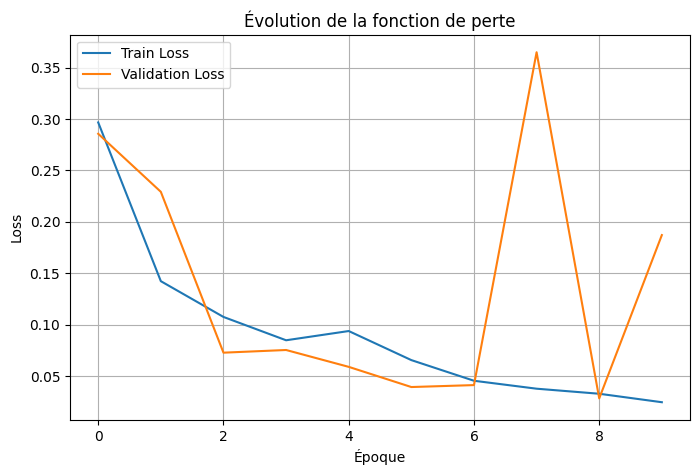

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la fonction de perte")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
print(X_test.shape)

probabilities = model.predict(X_test, verbose=0).ravel()

y_pred = (probabilities >= 0.5).astype(int)

print("F1-score:", f1_score(y_test, y_pred))

scores = model.evaluate(X_test, y_test, return_dict = True)

print(scores)

roc_auc_score_ = roc_auc_score(y_test, y_pred)


(624, 180, 180, 3)


2026-10-26 09:36:35.432681: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{} for conv %cudnn-conv-bias-activation.9 = (f32[32,32,178,178]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,3,180,180]{3,2,1,0} %bitcast.226, f32[32,3,3,3]{3,2,1,0} %bitcast.233, f32[32]{0} %bitcast.235), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", metadata={op_type="Conv2D" op_name="sequential_1/conv2d_1/convolution" source_file="/venv/main/lib/python3.10/site-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kRelu","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false}
2026-10-26 09:36:35.475391: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{

F1-score: 0.8590604026845637
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8103 - auc: 0.8850 - loss: 0.9967 - precision: 0.7677 - recall: 0.9910  
{'accuracy': 0.7980769276618958, 'auc': 0.8788955211639404, 'loss': 1.0566215515136719, 'precision': 0.761904776096344, 'recall': 0.9846153855323792}


# initialisation

In [20]:
path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)


In [21]:
path = Path(path)

In [22]:
train_path = os.path.join(path,"chest_xray/chest_xray","train")
test_path = os.path.join(path,"chest_xray/chest_xray","test")
val_path = os.path.join(path,"chest_xray/chest_xray","val")


In [23]:
train_ds = image_dataset_from_directory(
    train_path,
    labels='inferred',
    label_mode = "binary",
    color_mode = "rgb",
    shuffle = True,
    seed = 42
)

test_ds = image_dataset_from_directory(
    test_path,
    labels='inferred',
    label_mode = "binary",
    color_mode = "rgb",
    shuffle = False,
    seed = 42
)

val_ds = image_dataset_from_directory(
    val_path,
    labels='inferred',
    label_mode = "binary",
    color_mode = "rgb",
    shuffle = False,
    seed = 42
)

Found 5216 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Found 16 files belonging to 2 classes.


In [24]:
def class_weight() :
    y_train = np.concatenate([
        labels.numpy() for image,labels in train_ds   
    ]).flatten()

    classes = np.array([0 if name == "NORMAL" else 1
               for name in train_ds.class_names])

    weights = compute_class_weight(class_weight="balanced",classes=classes,y=y_train)

    classes_weights = dict(zip(classes,weights))

    return classes_weights

computed_class_weight = class_weight()

2026-10-26 09:36:50.641247: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [25]:
early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

checkpoint = ModelCheckpoint(
    "best_pneumonia_model.keras",
    monitor="val_loss",
    save_best_only=True
)


reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.1,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

In [26]:
def train_model_save(model, name, eta= 1e-3, save = False):
    model.compile(
        optimizer = keras.optimizers.Adam(eta),
        loss = "binary_crossentropy",
        metrics = [
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ]
    )    
    history = model.fit(    
        train_ds,
        epochs=5,
        batch_size=32,
        class_weight = computed_class_weight,
        validation_data=val_ds,
        callbacks = [early_stopping, reduce_lr, checkpoint]
    )
    if save:
        model.save(name)
    return history

# cnn

In [27]:
cnn_model = keras.Sequential([
   
    keras.Input(shape=(None, None, 3)),
    
    layers.Resizing(180, 180),  
    
    layers.Rescaling(1./255), 
     
    # Feature extraction
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Binary output
    layers.Dense(1, activation="sigmoid")
])

cnn_history = train_model_save(cnn_model, "/workspace/cnn_model.keras", eta=1e-3, save=True)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 18s 53ms/step - accuracy: 0.7775 - auc: 0.8460 - loss: 0.5802 - precision: 0.9148 - recall: 0.7588 - val_accuracy: 0.9375 - val_auc: 0.9844 - val_loss: 0.1986 - val_precision: 0.8889 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 13s 79ms/step - accuracy: 0.9549 - auc: 0.9893 - loss: 0.1254 - precision: 0.9867 - recall: 0.9514 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.1405 - val_precision: 0.8889 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 13s 79ms/step - accuracy: 0.9565 - auc: 0.9922 - loss: 0.1093 - precision: 0.9869 - recall: 0.9533 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0626 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 15s 88ms/step - accuracy: 0.9715 - auc: 0.9958 - loss: 0.0779 - precision: 0.9899 - recall: 0.9709 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0371 -

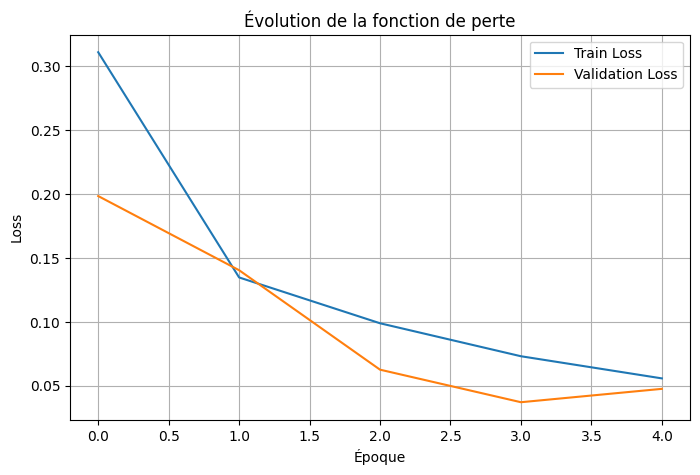

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(cnn_history.history["loss"], label="Train Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la fonction de perte")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
import os

path = "/workspace/cnn_model.keras"

if cnn_model is not None:
    cnn_model.save(path)
    print("Model saved successfully!")
else:
    print("No model!")

Model saved successfully!


# MobileV2

In [30]:
base_model_tl = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)
base_model_tl.trainable = False

/tmp/ipykernel_961/3571261794.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model_tl = MobileNetV2(


In [31]:
tl_model =  keras.Sequential([
    layers.Input((None, None, 3)),
    layers.Resizing(180, 180),
    layers.Rescaling(scale=1./127.5, offset=-1.),
    base_model_tl,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

In [32]:
history = train_model_save(tl_model,"/workspace/tl_model.keras",save=True)


Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 26s 73ms/step - accuracy: 0.8440 - auc: 0.9209 - loss: 0.3537 - precision: 0.9412 - recall: 0.8355 - val_accuracy: 0.9375 - val_auc: 0.9844 - val_loss: 0.1925 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 11s 68ms/step - accuracy: 0.9423 - auc: 0.9887 - loss: 0.1451 - precision: 0.9877 - recall: 0.9329 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.1529 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.9531 - auc: 0.9921 - loss: 0.1185 - precision: 0.9885 - recall: 0.9475 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.1358 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.9619 - auc: 0.9930 - loss: 0.1052 - precision: 0.9922 - recall: 0.9557 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1251 -

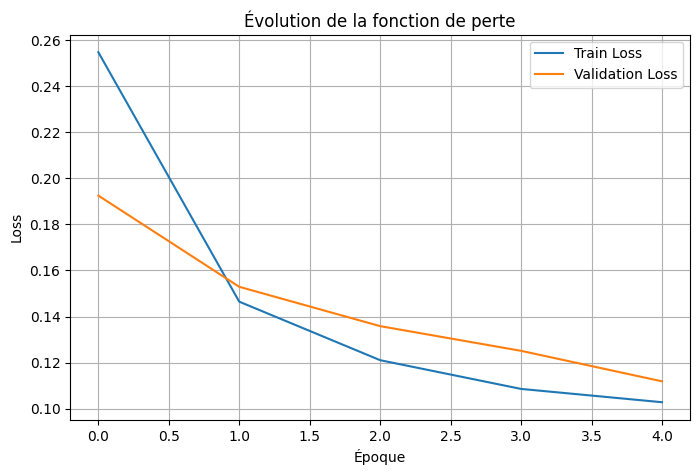

In [33]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la fonction de perte")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
base_model_tl.trainable = True

for layer in base_model_tl.layers[:-20] :
    layer.trainable = False

In [35]:
tl_model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=1e-5),
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)

In [36]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=2
    ),

    keras.callbacks.ModelCheckpoint(
        "/workspace/best_finetuned_model.keras",
        monitor = "val_loss",
        save_best_only = True
    )
]

In [37]:
history_ft = tl_model.fit(
    train_ds,
    validation_data = val_ds,
    epochs = 5,
    callbacks = callbacks
)

Epoch 1/5


2026-10-26 09:39:23.566787: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 09:39:23.707346: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


163/163 ━━━━━━━━━━━━━━━━━━━━ 26s 83ms/step - accuracy: 0.8575 - loss: 0.3789 - val_accuracy: 0.9375 - val_loss: 0.1575 - learning_rate: 1.0000e-05
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - accuracy: 0.9564 - loss: 0.1132 - val_accuracy: 0.8750 - val_loss: 0.2112 - learning_rate: 1.0000e-05
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.9663 - loss: 0.0785 - val_accuracy: 0.8750 - val_loss: 0.2402 - learning_rate: 1.0000e-05
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - accuracy: 0.9773 - loss: 0.0654 - val_accuracy: 0.8750 - val_loss: 0.2119 - learning_rate: 1.0000e-06


In [38]:
print("Best TL Accuracy:", max(history.history["val_accuracy"]))
print("Best FT Accuracy:", max(history_ft.history["val_accuracy"]))

print("Best TL Loss:", min(history.history["val_loss"]))
print("Best FT Loss:", min(history_ft.history["val_loss"]))

Best TL Accuracy: 1.0
Best FT Accuracy: 0.9375
Best TL Loss: 0.11186448484659195
Best FT Loss: 0.15746594965457916


In [39]:
test_loss,test_accuracy = tl_model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.7130 - loss: 0.9920 
Test Accuracy: 0.8317307829856873
Test Loss: 0.6039626002311707


In [40]:
y_true = np.concatenate([
    labels.numpy().flatten()
    for images,labels in test_ds
])

y_prob = tl_model.predict(test_ds).flatten()
y_pred = (y_prob>=0.5).astype(int)

2026-10-26 09:40:14.286464: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 243ms/step


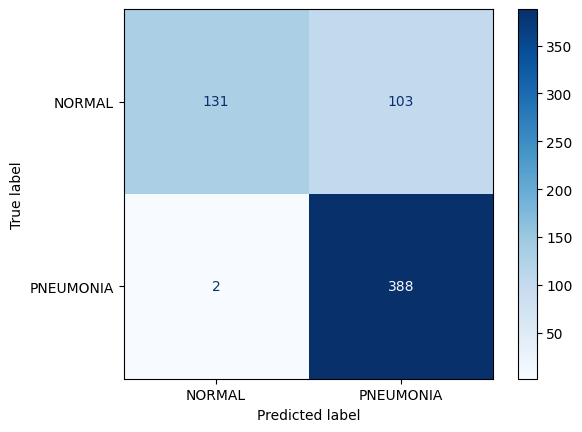

In [41]:
cm = confusion_matrix(y_true,y_pred)

ConfusionMatrixDisplay(
    confusion_matrix= cm,
    display_labels=["NORMAL","PNEUMONIA"]
).plot(cmap="Blues")

plt.show()

In [42]:
print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"]
))

              precision    recall  f1-score   support

      NORMAL       0.98      0.56      0.71       234
   PNEUMONIA       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.89      0.78      0.80       624
weighted avg       0.86      0.83      0.82       624



In [43]:
cnn = keras.models.load_model("/workspace/cnn_model.keras")
tl = keras.models.load_model("/workspace/tl_model.keras")
ft = keras.models.load_model("/workspace/best_finetuned_model.keras")

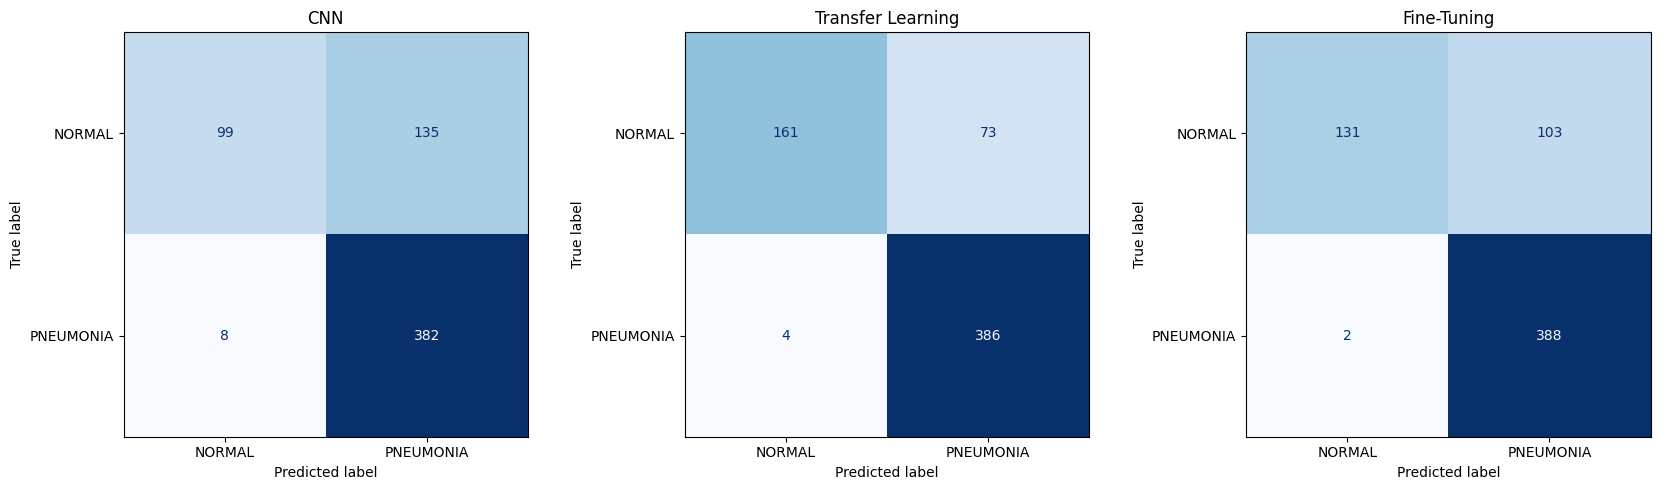

In [44]:

models = {
    "CNN": cnn,
    "Transfer Learning": tl,
    "Fine-Tuning": ft
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Récupérer les vraies étiquettes dans l'ordre du test
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

for ax, (name, model) in zip(axes, models.items()):

    y_pred = (model.predict(test_ds, verbose=0).ravel() >= 0.5).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["NORMAL", "PNEUMONIA"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [45]:
for name, model in models.items():
    y_pred = (model.predict(test_ds, verbose=0).flatten() >= 0.5).astype(int)

    print(f"\n===== {name} =====")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"]
    ))


===== CNN =====
              precision    recall  f1-score   support

      NORMAL       0.93      0.42      0.58       234
   PNEUMONIA       0.74      0.98      0.84       390

    accuracy                           0.77       624
   macro avg       0.83      0.70      0.71       624
weighted avg       0.81      0.77      0.74       624


===== Transfer Learning =====
              precision    recall  f1-score   support

      NORMAL       0.98      0.69      0.81       234
   PNEUMONIA       0.84      0.99      0.91       390

    accuracy                           0.88       624
   macro avg       0.91      0.84      0.86       624
weighted avg       0.89      0.88      0.87       624


===== Fine-Tuning =====
              precision    recall  f1-score   support

      NORMAL       0.98      0.56      0.71       234
   PNEUMONIA       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.89      0.78      0.80       624
w

In [46]:
y_prob = tl.predict(test_ds, verbose=0).flatten()
y_pred = (y_prob >= 0.5).astype(int)

errors = np.where(y_true != y_pred)[0]


print("Images mal classifiées :", len(errors))

Images mal classifiées : 77


2026-10-26 09:40:50.721344: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


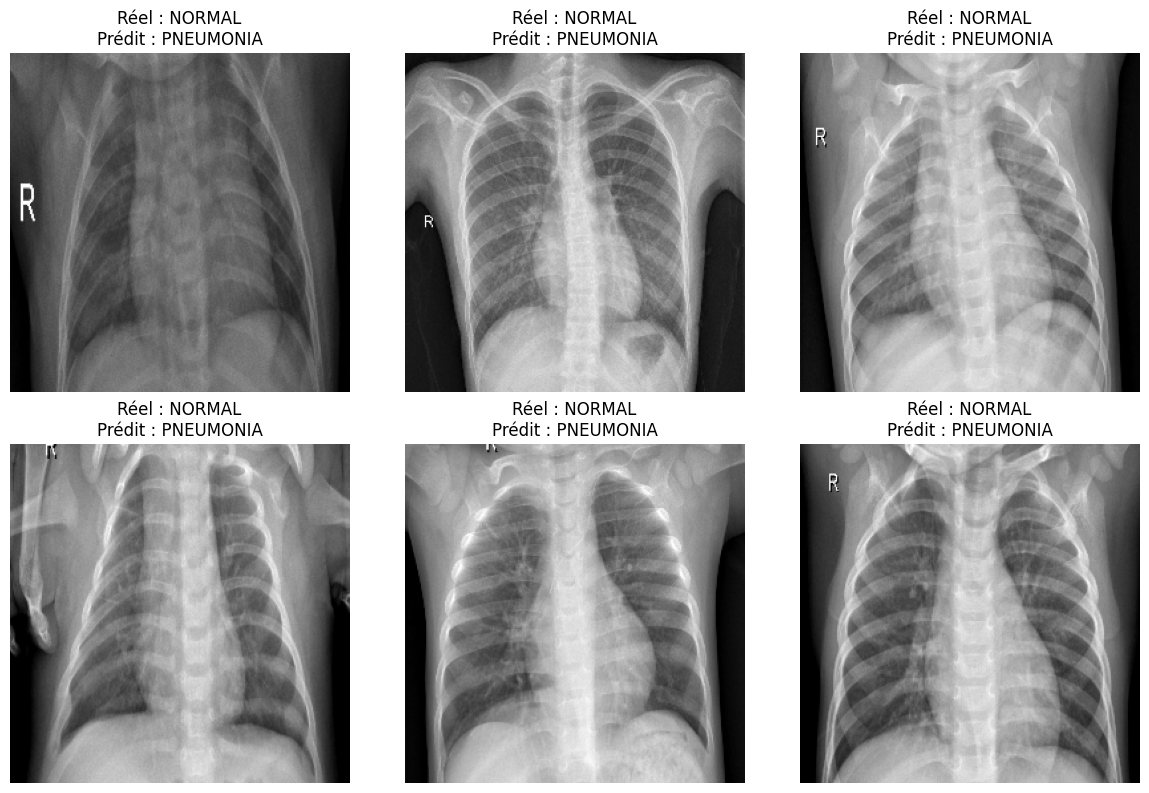

In [47]:
images = np.concatenate([
    batch_images.numpy()
    for batch_images, labels in test_ds
])

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

classes = ["NORMAL", "PNEUMONIA"]

for ax, idx in zip(axes.flat, errors[:6]):
    ax.imshow(images[idx].astype("uint8"))
    ax.set_title(
        f"Réel : {classes[y_true[idx]]}\n"
        f"Prédit : {classes[y_pred[idx]]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [48]:
def predict_image(image_path, model):
    img = load_img(image_path, target_size=(180, 180))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    probability = model.predict(img_array, verbose=0)[0][0]

    prediction = "PNEUMONIA" if probability >= 0.5 else "NORMAL"

    print("Prediction:", prediction)
    print("Probability PNEUMONIA:", round(float(probability), 4))

In [49]:
from pathlib import Path

image_path = next(Path(test_path, "NORMAL").glob("*.jpeg"))

predict_image(str(image_path), ft)

Prediction: NORMAL
Probability PNEUMONIA: 0.0205


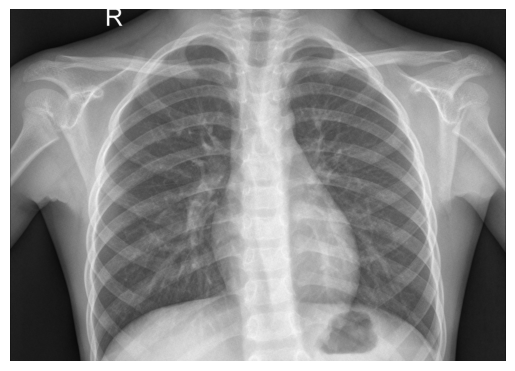

In [50]:
plt.imshow(Image.open(image_path), cmap="gray")
plt.axis("off")
plt.show()

In [51]:
from pathlib import Path


Path("/workspace/models").mkdir(exist_ok=True)

model.save("/workspace/models/tl_model.keras")

print("Modèle sauvegardé !")

Modèle sauvegardé !


In [52]:
from tensorflow.keras.models import load_model

model = load_model("/workspace/models/tl_model.keras")
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_1 (Resizing)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,673,989 (17.83 MB)

 Trainable params: 1,207,361 (4.61 MB)

 Non-trainable params: 1,051,904 (4.01 MB)

 Optimizer params: 2,414,724 (9.21 MB)

In [53]:
results = model.evaluate(test_ds, return_dict=True)

for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 146ms/step - accuracy: 0.7130 - loss: 0.9920
accuracy: 0.8317
loss: 0.6040
